# TP3 - Prompting

Objectif : retrouver quel personnage dit une réplique, en utilisant un LLM avec un prompt (sans l'entraîner).

In [1]:
# librairies
import re
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# graine fixe pour retrouver les mêmes résultats
SEED = 42
torch.manual_seed(SEED)

## 1. Les données

In [2]:
# téléchargement du corpus
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(url).read().decode("utf-8")

lignes = []
# les blocs sont séparés par une ligne vide
for bloc in texte.split("\n\n"):
    parties = bloc.strip().split("\n")
    # la 1ere ligne doit etre de la forme "NOM:"
    entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
    if entete and len(parties) > 1:
        lignes.append({
            "locuteur": entete.group(1).strip(),
            "replique": " ".join(p.strip() for p in parties[1:]).strip(),
        })

df = pd.DataFrame(lignes)
print(len(df), "répliques")
df.head()

7094 répliques


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."


In [3]:
# on enlève les répliques trop courtes (moins de 5 mots)
df = df[df["replique"].str.split().str.len() >= 5]
# et les doublons
df = df.drop_duplicates(subset="replique")

# on garde les 5 personnages qui parlent le plus
top5 = df["locuteur"].value_counts().head(5).index
donnees = df[df["locuteur"].isin(top5)]
classes = sorted(top5)

print(donnees["locuteur"].value_counts())

locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64


In [4]:
# 20% pour le test (même découpage qu'au TP1)
train_complet, test = train_test_split(
    donnees, test_size=0.2, stratify=donnees["locuteur"], random_state=SEED)

# 100 répliques de validation pour choisir le prompt
train, val = train_test_split(
    train_complet, test_size=100, stratify=train_complet["locuteur"], random_state=SEED)

print("train :", len(train), "| validation :", len(val), "| test :", len(test))

train : 508 | validation : 100 | test : 153


## 2. Prompting

Deux prompts à comparer :
- zero-shot : seulement la consigne
- few-shot : la consigne + des exemples

In [5]:
# consigne en anglais car le texte est en anglais
liste_noms = ", ".join(classes)
CONSIGNE = (
    "You are given a line from a Shakespeare play. "
    f"Who says it? Choose one name from this list: {liste_noms}. "
    "Answer only with the name, written exactly as in the list."
)
print(CONSIGNE)

You are given a line from a Shakespeare play. Who says it? Choose one name from this list: DUKE VINCENTIO, GLOUCESTER, MENENIUS, PETRUCHIO, ROMEO. Answer only with the name, written exactly as in the list.


In [6]:
def prompt_zero_shot(replique):
    # system = les règles, user = la question
    return [
        {"role": "system", "content": CONSIGNE},
        {"role": "user", "content": f"Line: {replique}"},
    ]

In [7]:
# exemples pris dans le train (jamais dans le test)
# on prend des répliques pas trop longues pour garder un prompt court
courtes = train[train["replique"].str.split().str.len() <= 40]
exemples = courtes.groupby("locuteur").sample(2, random_state=SEED)  # 2 par personnage
exemples = exemples.sample(frac=1, random_state=SEED)                # on mélange


def prompt_few_shot(replique):
    messages = [{"role": "system", "content": CONSIGNE}]
    # chaque exemple = une question puis la bonne réponse
    for _, ex in exemples.iterrows():
        messages.append({"role": "user", "content": f"Line: {ex['replique']}"})
        messages.append({"role": "assistant", "content": ex["locuteur"]})
    # à la fin, la vraie question
    messages.append({"role": "user", "content": f"Line: {replique}"})
    return messages

## 3. Le modèle LLM

On utilise Qwen2.5-1.5B-Instruct : un petit modèle gratuit, dont les poids sont téléchargeables, qui tourne sur le GPU de Colab.

In [8]:
NOM_MODELE = "Qwen/Qwen2.5-1.5B-Instruct"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device :", device)  # il faut cuda, sinon c'est très lent

# le tokenizer transforme le texte en nombres
tokenizer = AutoTokenizer.from_pretrained(NOM_MODELE)

# float16 prend moins de mémoire sur GPU
modele = AutoModelForCausalLM.from_pretrained(
    NOM_MODELE,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
).to(device)
modele.eval()  # pas d'entraînement ici

device : cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((1536,), eps=1e-06)
    (rotar

In [9]:
def generer(messages):
    # mise au format de discussion attendu par le modèle
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    entrees = tokenizer(prompt, return_tensors="pt").to(device)

    with torch.no_grad():
        sortie = modele.generate(
            **entrees,
            max_new_tokens=10,   # un nom c'est court
            do_sample=False,     # pas de hasard, on prend le token le plus probable
            pad_token_id=tokenizer.eos_token_id,
        )

    # on garde seulement la partie ajoutée par le modèle
    nouveaux = sortie[0][entrees["input_ids"].shape[1]:]
    return tokenizer.decode(nouveaux, skip_special_tokens=True).strip()

## 4. Sorties générées

In [10]:
def extraire_nom(reponse):
    # quels noms de la liste sont dans la réponse ?
    trouves = [c for c in classes
               if re.search(r"\b" + re.escape(c.lower()) + r"\b", reponse.lower())]
    # aucun nom ou plusieurs noms : réponse invalide
    if len(trouves) == 1:
        return trouves[0]
    return "invalide"

In [11]:
# petit test sur 3 répliques pour voir ce que ça donne
for _, ligne in val.head(3).iterrows():
    print("Réplique  :", ligne["replique"][:200])
    print("Vrai      :", ligne["locuteur"])
    print("Zero-shot :", generer(prompt_zero_shot(ligne["replique"])))
    print("Few-shot  :", generer(prompt_few_shot(ligne["replique"])))
    print()

Réplique  : This forenamed maid hath yet in her the continuance of her first affection: his unjust unkindness, that in all reason should have quenched her love, hath, like an impediment in the current, made it mo
Vrai      : DUKE VINCENTIO
Zero-shot : ANGELO
Few-shot  : ROMEO

Réplique  : Fairer than tongue can name thee, let me have Some patient leisure to excuse myself.
Vrai      : GLOUCESTER
Zero-shot : ROMEO
Few-shot  : ROMEO

Réplique  : Signior Hortensio, 'twixt such friends as we Few words suffice; and therefore, if thou know One rich enough to be Petruchio's wife, As wealth is burden of my wooing dance, Be she as foul as was Floren
Vrai      : PETRUCHIO
Zero-shot : PETRUCHIO
Few-shot  : ROMEO



## 5. Évaluation

In [12]:
def predire(fonction_prompt, jeu):
    # une génération par réplique
    reponses = [generer(fonction_prompt(r)) for r in jeu["replique"]]
    preds = [extraire_nom(r) for r in reponses]
    return reponses, preds


def calculer_scores(vrai, preds):
    return {
        "accuracy": accuracy_score(vrai, preds),
        # une réponse invalide compte comme une erreur
        "f1 macro": f1_score(vrai, preds, labels=classes, average="macro", zero_division=0),
        "part invalides": list(preds).count("invalide") / len(preds),
    }

In [13]:
# on choisit le prompt sur la validation, pas sur le test
prompts = {"zero-shot": prompt_zero_shot, "few-shot": prompt_few_shot}

scores_val = {}
for nom, fonction in prompts.items():
    _, preds = predire(fonction, val)
    scores_val[nom] = calculer_scores(val["locuteur"], preds)

meilleur = max(scores_val, key=lambda n: scores_val[n]["f1 macro"])
print("meilleur prompt :", meilleur)
pd.DataFrame(scores_val).T.round(3)

meilleur prompt : zero-shot


,accuracy,f1 macro,part invalides
zero-shot,0.28,0.184,0.04
few-shot,0.25,0.143,0.00


In [14]:
# évaluation finale sur le test (ça prend quelques minutes)
reponses_test, preds_test = predire(prompts[meilleur], test)

In [15]:
# pour comparer : une baseline et un modèle classique comme au TP1

# baseline : toujours répondre le personnage le plus fréquent
majoritaire = train_complet["locuteur"].mode()[0]
preds_base = [majoritaire] * len(test)

# TF-IDF + régression logistique, appris sur le train
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(train_complet["replique"])
X_test = tfidf.transform(test["replique"])  # transform seulement
logreg = LogisticRegression(class_weight="balanced", max_iter=5000)
logreg.fit(X_train, train_complet["locuteur"])

tableau = pd.DataFrame({
    "baseline": calculer_scores(test["locuteur"], preds_base),
    "TF-IDF + LogReg": calculer_scores(test["locuteur"], logreg.predict(X_test)),
    "LLM " + meilleur: calculer_scores(test["locuteur"], preds_test),
}).T
tableau.round(3)

,accuracy,f1 macro,part invalides
baseline,0.261,0.083,0.000
TF-IDF + LogReg,0.667,0.668,0.000
LLM zero-shot,0.255,0.174,0.033


In [16]:
# précision, rappel et f1 pour chaque personnage
print(classification_report(test["locuteur"], preds_test, labels=classes, zero_division=0))

                precision    recall  f1-score   support

DUKE VINCENTIO       0.23      0.58      0.33        33
    GLOUCESTER       0.00      0.00      0.00        40
      MENENIUS       0.00      0.00      0.00        25
     PETRUCHIO       0.29      0.07      0.12        27
         ROMEO       0.32      0.64      0.42        28

     micro avg       0.26      0.25      0.26       153
     macro avg       0.17      0.26      0.17       153
  weighted avg       0.16      0.25      0.17       153



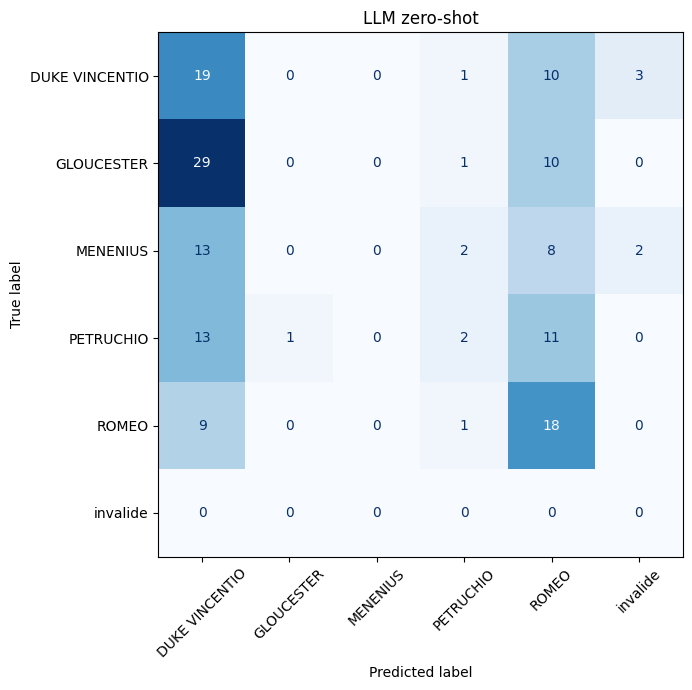

In [17]:
# matrice de confusion (avec la colonne invalide s'il y en a)
etiquettes = classes + (["invalide"] if "invalide" in preds_test else [])

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    test["locuteur"], preds_test, labels=etiquettes,
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("LLM " + meilleur)
plt.tight_layout()
plt.show()

In [18]:
# quelques erreurs pour comprendre
erreurs = test.assign(reponse=reponses_test, pred=preds_test)
erreurs = erreurs[erreurs["locuteur"] != erreurs["pred"]]
print(len(erreurs), "erreurs sur", len(test))

for _, e in erreurs.head(5).iterrows():
    print("Vrai :", e["locuteur"], "| Réponse du modèle :", e["reponse"])
    print(e["replique"][:300])
    print()

114 erreurs sur 153
Vrai : ROMEO | Réponse du modèle : DUKE VINCENTIO
Switch and spurs, switch and spurs; or I'll cry a match.

Vrai : PETRUCHIO | Réponse du modèle : ROMEO
Why, thou say'st true; it is a paltry cap, A custard-coffin, a bauble, a silken pie: I love thee well, in that thou likest it not.

Vrai : PETRUCHIO | Réponse du modèle : ROMEO
Twenty crowns! I'll venture so much of my hawk or hound, But twenty times so much upon my wife.

Vrai : MENENIUS | Réponse du modèle : DUKE VINCENTIO
Cannot be! We have record that very well it can, And three examples of the like have been Within my age. But reason with the fellow, Before you punish him, where he heard this, Lest you shall chance to whip your information And beat the messenger who bids beware Of what is to be dreaded.

Vrai : GLOUCESTER | Réponse du modèle : DUKE VINCENTIO
By so much is the wonder in extremes.



## Conclusion


- **Meilleur prompt :** le zero-shot, avec un F1 macro de 0,184 contre 0,143 pour le few-shot sur la validation (accuracy 28 % contre 25 %). Les exemples n'ont pas aidé. L'écart reste petit : 3 répliques sur 100. En revanche, le few-shot n'a donné aucune réponse invalide, contre 4 % pour le zero-shot.
- **Par rapport à la baseline et au TF-IDF (test) :** le LLM a une accuracy de 25,5 %, un peu sous la baseline (26,1 %). Son F1 macro est meilleur (0,174 contre 0,083), mais reste très loin du TF-IDF + régression logistique (accuracy 66,7 %, F1 macro 0,668).
- **Personnages les plus confondus :** le modèle répond presque toujours Duke Vincentio (83 fois) ou Romeo (57 fois) sur 153 répliques. Gloucester est pris pour Duke Vincentio 29 fois sur 40. Gloucester et Menenius ne sont jamais reconnus. Il y a aussi 5 réponses invalides (3,3 %).
- **Explication possible :** le modèle est petit (1,5 milliard de paramètres) et semble choisir les noms qui lui sont les plus familiers plutôt que d'analyser la réplique. Le TF-IDF, lui, a appris sur des répliques étiquetées de ces 5 personnages.
- **Limite :** Qwen a sûrement déjà vu du Shakespeare pendant son entraînement, donc la comparaison avec le modèle classique n'est pas complètement équitable. Malgré cela, il fait beaucoup moins bien.